# Multi-order hypergraphs: recovery curves and transition boundaries

Read saved experiment results to compare order sets, fixed-budget experiments, and signal compensation. **Run cells from top to bottom**; routine adjustments are in Section 1.

- The first experiment uses N=30000 and five samples, with the original `overlap` metric.
- Shaded bands show standard deviations across seeds (`ddof=0`), rather than standard errors or confidence intervals.
- Transition formulas, empirical thresholds, and time units follow the original definitions. Linear-stability boundaries and empirical `Overlap=0.1` boundaries are labeled separately.
- Display five main figures and numerical tables by default. Optional signal diagnostics can be enabled. Export 600 dpi PNG, PDF with embedded fonts, SVG with editable text, and separate captions.

## 1. Configuration

Input paths are explicit. Each run creates a timestamped output directory; source NPZ files are preserved.

In [1]:
from pathlib import Path
from datetime import datetime

PROJECT_ROOT = next(
    (parent for parent in (Path.cwd(), *Path.cwd().parents)
     if (parent / "main_plot.ipynb").is_file() and (parent / "plot_data").is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Run this notebook from the repository root or a directory inside it.")
ORDER_DATA_DIR = PROJECT_ROOT / "plot_data/main_plot"
ORDER_FILE = ORDER_DATA_DIR / "final_results_hsbm_approx_with_overlap_active.npz"
EXPECTED_ORDER_N, EXPECTED_ORDER_SEEDS = 30000, 5
FIXED_BUDGET_DIR = PROJECT_ROOT / "plot_data/main_plot"
FIXED_BUDGET_FILES = [
    FIXED_BUDGET_DIR / f"final_results_fixed_budget_D2_3_N10000_K4_c010_kbar{k}_seeds5.npz"
    for k in (3, 12)
]
SIGNAL_DIR = PROJECT_ROOT / "plot_data/main_plot"
# Historical mean4 filenames contain five seeds; read seed_ids for the actual count.
SIGNAL_FILE = SIGNAL_DIR / "final_results_signal_compensation_D2_3_kbar8_ALLR_mean4.npz"

OUTPUT_ROOT = PROJECT_ROOT / "outputs/main_plot"
OUTPUT_DIR = OUTPUT_ROOT / datetime.now().strftime("%Y%m%d_%H%M%S_%f")
FIGURE_FORMATS = ("png", "pdf", "svg")

K, C_2 = 4, 10
TARGET_ORDER_SETS = [(2, 3, 4, 5, 6), (2, 3, 4, 5, 16),
                     (2, 3, 4, 15, 16), (2, 3, 15, 16, 17), (2, 14, 15, 16, 17)]
OVERLAP_METRIC = "overlap"  # Retain the original metric, which differs from overlap_active.
STD_DDOF = 0               # Retain the original convention; signal summaries also use ddof=0.
Q_LEVEL = 0.1
SHOW_OLD_APPROXIMATION = False
THEORY_KBAR_VALUES = (3., 8.)
SELECTED_X = (0.5, 4, 8, 20)

SHOW_SIGNAL_DIAGNOSTICS = False
REBUILD_SIGNAL_SUMMARY = False  # Rebuild summaries from existing results without running BP/EM.
SIGNAL_SEED_IDS = (1, 2, 3, 4, 5)
SIGNAL_R_TAGS = {1.: "1.000000", 2.2125154076: "2.212515", 3.: "3.000000"}

## 2. Shared functions

The three function cells handle statistics/export, fixed-budget boundaries, and signal compensation. They can be collapsed. Plot cells reuse the loaded data instead of maintaining five separate variable groups.

`compute_epsilon_c` returns the original linear approximation; `epsilon_c_phys` truncates it at zero. Fixed-budget plots do not draw a zero boundary where the theoretical result is negative.

In [2]:
"""Shared plotting, statistics, and exports for main_plot.ipynb."""
import hashlib
import json
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import FormatStrFormatter

try:
    from IPython.display import display, HTML
except ImportError:
    display = print
    HTML = str

PALETTE = ['#4C84B8', '#D2691E', '#45A581', '#C77DB1', '#E2A515']
PAPER_STYLE = {
    'font.family': 'DejaVu Sans', 'mathtext.fontset': 'stix',
    'text.usetex': False, 'font.size': 8, 'axes.labelsize': 9,
    'axes.titlesize': 9, 'xtick.labelsize': 8, 'ytick.labelsize': 8,
    'legend.fontsize': 7, 'axes.linewidth': .7, 'lines.linewidth': 1.3,
    'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'pdf.fonttype': 42, 'ps.fonttype': 42, 'svg.fonttype': 'none',
    'savefig.facecolor': 'white',
}


def style_axes(ax, grid=True):
    ax.spines[['top', 'right']].set_visible(False)
    ax.tick_params(direction='out', width=.7, length=3)
    ax.set_axisbelow(True)
    if grid:
        ax.grid(color='.9', linewidth=.5, alpha=.65)


def source_record(path):
    path = Path(path)
    return {'path': str(path.resolve()), 'sha256': hashlib.sha256(path.read_bytes()).hexdigest()}


def save_figure(fig, stem, caption, sources=()):
    """Save a vector master and high resolution raster, with a separate caption."""
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    for suffix in FIGURE_FORMATS:
        with plt.rc_context(PAPER_STYLE):
            fig.savefig(OUTPUT_DIR / f'{stem}.{suffix}', dpi=600,
                        bbox_inches='tight', pad_inches=.05)
    (OUTPUT_DIR / f'{stem}_caption.txt').write_text(caption + '\n', encoding='utf-8')
    record = {'stem': stem, 'caption': caption, 'sources': [source_record(p) for p in sources],
              'statistics_ddof': STD_DDOF, 'png_dpi': 600,
              'figure_size_mm': (np.asarray(fig.get_size_inches()) * 25.4).tolist()}
    (OUTPUT_DIR / f'{stem}_provenance.json').write_text(
        json.dumps(record, ensure_ascii=False, indent=2), encoding='utf-8')
    display(fig)
    plt.close(fig)


def save_table(rows, stem, precision=5):
    table = pd.DataFrame(rows)
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    table.to_csv(OUTPUT_DIR / f'{stem}.csv', index=False, encoding='utf-8-sig')
    display(HTML(table.to_html(index=False, float_format=lambda x: f'{x:.{precision}g}',
                              border=0, classes='dataframe')))
    return table


def validate_layer_parameters(selected_hye_sizes, beta, K, c_2):
    orders = np.asarray(selected_hye_sizes, dtype=float)
    beta = np.asarray(beta, dtype=float)
    if orders.ndim != 1 or orders.size == 0 or beta.shape != orders.shape:
        raise ValueError('orders 和 beta 必须是相同长度的非空一维数组。')
    if not np.isfinite(orders).all() or np.any(orders < 2) or np.any(orders != np.floor(orders)):
        raise ValueError('超边阶数必须是大于等于2的有限整数。')
    if len(np.unique(orders)) != len(orders):
        raise ValueError('超边阶数不能重复。')
    if not np.isfinite(beta).all() or np.any(beta < 0) or beta.sum() <= 0:
        raise ValueError('beta 必须有限、非负且至少有一项大于0。')
    if not np.isfinite(K) or K < 2 or K != int(K) or not np.isfinite(c_2) or c_2 <= 0:
        raise ValueError('K 必须是大于等于2的整数，c_2 必须为正数。')
    return orders, beta


def compute_epsilon_c(selected_hye_sizes, beta, K=4, c_2=10):
    """Original order-resolved linear threshold; return the raw epsilon."""
    orders, beta = validate_layer_parameters(selected_hye_sizes, beta, K, c_2)
    contribution = beta * (2 / (orders * (orders - 1)))**2
    S_order = np.sum(contribution)
    gamma = 1 / np.sqrt(S_order)
    lambda_c = 1 / np.sqrt(c_2 * S_order)
    phi = ((K - 1) / K) * (1 / np.sqrt(c_2)) * gamma
    eps_c = (1 / (phi + 1 / K) - 1) / (K - 1)
    return eps_c, S_order, gamma, lambda_c, contribution


def compute_epsilon_c_old(selected_hye_sizes, beta, K=4, c_2=10):
    """Original geometric aggregate approximation, retained for comparison."""
    orders, beta = validate_layer_parameters(selected_hye_sizes, beta, K, c_2)
    C_beta = np.sum(2 * beta / (orders - 1))
    P_d = beta / (orders * (orders - 1))
    P_d = P_d / np.sum(P_d)
    F = np.sum(orders * P_d)
    gamma = np.exp(np.sum(P_d * np.log(orders * (orders - 1) / 2))) / np.sqrt(C_beta * (F - 1) / 2)
    phi = ((K - 1) / K) * (1 / np.sqrt(c_2)) * gamma
    eps_c = (1 / (phi + 1 / K) - 1) / (K - 1)
    return eps_c, C_beta, gamma, F, P_d


def load_order_sweep(path, target_order_sets, metric='overlap', ddof=0):
    """Load once; map curves by their actual orders, never by file position."""
    path = Path(path)
    with np.load(path, allow_pickle=True) as data:
        eps = np.asarray(data['eps_list'], dtype=float).copy()
        saved_orders = [tuple(int(d) for d in values) for values in data['selected_hye_sizes_list']]
        overlap = np.asarray(data[metric], dtype=float).copy()
        runtime = np.asarray(data['em_total_time'], dtype=float).copy()
        metadata = {key: np.asarray(data[key]).item() for key in ('N', 'K', 'c')}
        seeds = np.asarray(data['seed_sample_list']).copy()
        unit = str(np.asarray(data['em_total_time_unit']).item()) if 'em_total_time_unit' in data else 'seconds'
    if eps.ndim != 1 or eps.size < 2 or not np.isfinite(eps).all() or np.any(np.diff(eps) <= 0):
        raise ValueError('epsilon 坐标必须有限且严格递增。')
    expected = (len(seeds), len(eps), len(saved_orders))
    if overlap.shape != expected or runtime.shape != expected:
        raise ValueError(f'数据维度应为(seed, epsilon, order_set)={expected}。')
    if not np.isfinite(overlap).all() or not np.isfinite(runtime).all() or np.any(runtime < 0):
        raise ValueError('Overlap/运行时间含无效数值。')
    if np.any(overlap < -1e-10) or np.any(overlap > 1 + 1e-10):
        raise ValueError('Overlap 超出当前图定义的[0,1]范围。')
    if unit not in ('s', 'sec', 'seconds', 'second'):
        raise ValueError(f'预期时间单位为秒，文件记录为{unit}。')
    if not 0 <= ddof < len(seeds):
        raise ValueError('ddof 必须小于采样数。')
    targets = sorted(tuple(sorted(int(d) for d in values)) for values in target_order_sets)
    canonical_saved = [tuple(sorted(values)) for values in saved_orders]
    if len(set(canonical_saved)) != len(canonical_saved) or len(set(targets)) != len(targets):
        raise ValueError('阶数组合重复。')
    missing = set(targets) - set(canonical_saved)
    if missing:
        raise ValueError(f'文件中缺少阶数组合：{sorted(missing)}')
    indices = [canonical_saved.index(values) for values in targets]
    result = {'eps': eps, 'orders': targets, 'path': path, 'seeds': seeds,
              'metric': metric, 'ddof': ddof, **metadata}
    for name, values in [('overlap', overlap), ('time', runtime)]:
        result[name + '_all'] = values[:, :, indices]
        result[name + '_mean'] = np.mean(values, axis=0)[:, indices]
        result[name + '_std'] = np.std(values, axis=0, ddof=ddof)[:, indices]
    return result


def plot_order_sweep(dataset, metric='overlap', K=4, c_2=10, show_old=False):
    if K != dataset['K'] or not np.isclose(c_2, dataset['c']):
        raise ValueError('理论参数K/c_2与当前结果文件不一致。')
    if metric not in ('overlap', 'time'):
        raise ValueError('metric应为overlap或time。')
    with plt.rc_context(PAPER_STYLE):
        fig, ax = plt.subplots(figsize=(180 / 25.4, 120 / 25.4))
        for j, orders in enumerate(dataset['orders']):
            color = PALETTE[j % len(PALETTE)]
            scale = 60 if metric == 'time' else 1
            mean = dataset[metric + '_mean'][:, j] / scale
            std = dataset[metric + '_std'][:, j] / scale
            lower = np.maximum(mean - std, 0)
            upper = np.minimum(mean + std, 1) if metric == 'overlap' else mean + std
            label = r'$\{' + ','.join(map(str, orders)) + r'\}$'
            ax.fill_between(dataset['eps'], lower, upper, color=color, alpha=.15, linewidth=0)
            ax.plot(dataset['eps'], mean, color=color, marker='o', markersize=2.3,
                    markeredgewidth=0, markevery=2, label=label)
            beta = np.ones(len(orders))
            ax.axvline(compute_epsilon_c(orders, beta, K, c_2)[0], color=color,
                       ls='--', lw=.9, alpha=.85)
            if show_old:
                ax.axvline(compute_epsilon_c_old(orders, beta, K, c_2)[0], color=color,
                           ls=':', lw=.9, alpha=.85)
        handles, labels = ax.get_legend_handles_labels()
        handles.append(Line2D([], [], color='.35', ls='--', lw=1, label='Order-resolved boundary'))
        if show_old:
            handles.append(Line2D([], [], color='.35', ls=':', lw=1, label='Aggregate approximation'))
        ax.legend(handles=handles, loc='lower left' if metric == 'overlap' else 'best',
                  frameon=True, facecolor='white', edgecolor='.85', framealpha=.95)
        ax.set_xlabel(r'$\varepsilon=c_{\mathrm{out}}/c_{\mathrm{in}}$')
        ax.set_ylabel('Overlap' if metric == 'overlap' else 'EM runtime (min)')
        ax.set_xlim(0, max(dataset['eps']) + .005)
        ax.set_xticks(np.arange(0, max(dataset['eps']) + .001, .1))
        if metric == 'overlap':
            ax.set_ylim(-.025, 1.035)
            ax.set_yticks(np.arange(0, 1.01, .2))
            ax.yaxis.set_major_formatter(FormatStrFormatter('%.1f'))
        else:
            ax.set_ylim(bottom=0)
        ax.xaxis.set_major_formatter(FormatStrFormatter('%.1f'))
        style_axes(ax)
        fig.tight_layout(pad=.7)
    return fig


def order_threshold_rows(dataset, K=4, c_2=10):
    return [{'orders': '{' + ','.join(map(str, orders)) + '}',
             'epsilon_order_resolved': compute_epsilon_c(orders, np.ones(len(orders)), K, c_2)[0],
             'epsilon_aggregate': compute_epsilon_c_old(orders, np.ones(len(orders)), K, c_2)[0],
             'N': dataset['N'], 'seeds': len(dataset['seeds'])} for orders in dataset['orders']]


def growth_factor(x, d, kbar_h):
    x = np.asarray(x, dtype=float)
    return kbar_h * (1 + x * (2 / (d * (d - 1)))**2) / (1 + x / (d - 1))


def epsilon_c_phys(x, d, kbar_h, K=4):
    signal = 1 / np.sqrt(growth_factor(x, d, kbar_h))
    return np.maximum(0., (1 - signal) / (1 + (K - 1) * signal))


def epsilon_limit_x0(kbar_h, K=4):
    signal = 1 / np.sqrt(kbar_h)
    return max(0., (1 - signal) / (1 + (K - 1) * signal))


def epsilon_limit_xinf(d, kbar_h, K=4):
    signal = 1 / np.sqrt(4 * kbar_h / (d**2 * (d - 1)))
    return max(0., (1 - signal) / (1 + (K - 1) * signal))


def collapse_point(d, kbar_h):
    if kbar_h <= 1:
        return 0.
    if kbar_h < d**2 * (d - 1) / 4:
        return (kbar_h - 1) * d**2 * (d - 1)**2 / (d**2 * (d - 1) - 4 * kbar_h)
    return np.inf


def plot_theoretical_collapse(kbar_values=(3., 8.), d=3, K=4, x_max=50):
    x = np.linspace(0, x_max, 1000)
    with plt.rc_context(PAPER_STYLE):
        fig, ax = plt.subplots(figsize=(180 / 25.4, 115 / 25.4))
        for j, budget in enumerate(kbar_values):
            color = PALETTE[j % len(PALETTE)]
            ax.plot(x, epsilon_c_phys(x, d, budget, K), color=color,
                    label=rf'$\bar{{k}}_{{\mathrm{{h}}}}={budget:g}$')
            endpoint = epsilon_limit_x0(budget, K)
            limit = epsilon_limit_xinf(d, budget, K)
            ax.scatter(0, endpoint, color=color, s=16, clip_on=False, zorder=4)
            ax.annotate(rf'$\varepsilon_c(0)={endpoint:.3f}$', (0, endpoint),
                        xytext=(10, 8), textcoords='offset points', fontsize=7, color=color)
            ax.axhline(limit, ls=':', lw=.9, color=color)
            ax.text(.63 * x_max, limit + .008, rf'$\varepsilon_c(\infty)={limit:.3f}$',
                    color=color, fontsize=7)
            xc = collapse_point(d, budget)
            if 0 < xc < x_max:
                ax.axvline(xc, ls='--', lw=.9, color=color)
                ax.scatter(xc, 0, color=color, s=16, clip_on=False, zorder=4)
                ax.annotate(rf'$x_c={xc:g}$', (xc, 0), xytext=(12, 15),
                            textcoords='offset points', color=color, fontsize=7,
                            arrowprops={'arrowstyle': '->', 'color': color, 'lw': .6})
        ax.set(xlabel=rf'$x=\beta_{{{d}}}/\beta_2$', ylabel=r'$\varepsilon_c^{\mathrm{phys}}$',
               xlim=(0, x_max), ylim=(0, .35))
        ax.legend(loc='upper right', frameon=False)
        style_axes(ax)
        fig.tight_layout(pad=.7)
    return fig

In [3]:
def recovery_crossing(eps, overlap, threshold):
    """First downward threshold crossing, or the original scan-limit status."""
    eps = np.asarray(eps)
    overlap = np.asarray(overlap)
    if overlap[0] == threshold:
        return float(eps[0]), "crossing"
    if overlap[0] < threshold:
        if np.any(overlap[1:] >= threshold):
            return np.nan, "ambiguous_start"
        return float(eps[0]), "below_range"

    crossings = np.flatnonzero(
        (overlap[:-1] > threshold) & (overlap[1:] <= threshold)
    )
    if len(crossings) == 0:
        return float(eps[-1]), "above_range"
    j = int(crossings[0])
    value = eps[j] + (threshold - overlap[j]) * (eps[j + 1] - eps[j]) / (
        overlap[j + 1] - overlap[j]
    )
    status = "crossing" if len(crossings) == 1 else "crossing_multiple"
    return float(value), status


def theory_raw_D23(x, budget, K=4):
    """Unclipped D={2,3} boundary at fixed hyperedge-incidence budget."""
    x = np.asarray(x, dtype=float)
    growth = budget * (1 + x / 9) / (1 + x / 2)
    root = np.sqrt(growth)
    return (root - 1) / (root + K - 1)


def load_fixed_budget(paths, q_level=0.1):
    """Load mean overlaps and extract boundaries without changing censoring."""
    if not 0 < q_level < 1:
        raise ValueError("q_level must lie strictly between 0 and 1.")
    datasets, boundary_rows = [], []
    for path in paths:
        path = Path(path)
        with np.load(path, allow_pickle=False) as data:
            x = np.asarray(data["x_list"], dtype=float)
            eps = np.asarray(data["eps_list"], dtype=float)
            overlap = np.asarray(data["overlap_mean"], dtype=float)
            theory = np.asarray(data["eps_theory_phys"], dtype=float)
            raw = np.asarray(data["eps_theory_raw"], dtype=float)
            budget = float(np.asarray(data["kbar_h"]).item())
            node_count = int(np.asarray(data['N']).item()) if 'N' in data else None
            seed_count = len(data['overlap_all']) if 'overlap_all' in data else None

        if (
            x.ndim != 1
            or eps.ndim != 1
            or overlap.shape != (len(x), len(eps))
            or theory.shape != x.shape
            or raw.shape != x.shape
        ):
            raise ValueError(f"Inconsistent array dimensions: {path.name}")
        if not all(np.isfinite(a).all() for a in (x, eps, overlap, theory, raw)):
            raise ValueError(f"Nonfinite data: {path.name}")
        if not np.isfinite(budget) or budget <= 0:
            raise ValueError(f"Budget must be finite and positive: {path.name}")

        x_order, eps_order = np.argsort(x), np.argsort(eps)
        x, eps = x[x_order], eps[eps_order]
        overlap = overlap[np.ix_(x_order, eps_order)]
        theory, raw = theory[x_order], raw[x_order]
        positive = eps > 1e-12
        eps, overlap = eps[positive], overlap[:, positive]
        if (
            len(x) == 0
            or len(eps) < 2
            or np.any(np.diff(eps) <= 0)
            or np.any(np.diff(x) <= 0)
        ):
            raise ValueError(f"Repeated coordinates or insufficient samples: {path.name}")

        crossings = [recovery_crossing(eps, row, q_level) for row in overlap]
        empirical = np.asarray([value for value, _ in crossings])
        statuses = np.asarray([status for _, status in crossings])
        physical = np.where(raw >= -1e-12, theory, np.nan)
        for x_value, value, theory_value, status in zip(
            x, empirical, physical, statuses
        ):
            boundary_rows.append({
                "kbar_h": budget,
                "x": float(x_value),
                "empirical": float(value),
                "theory": float(theory_value),
                "status": str(status),
            })
        datasets.append({
            "x": x,
            "budget": budget,
            "theory": physical,
            "theory_raw": raw,
            "empirical": empirical,
            "status": statuses,
            "N": node_count,
            "seed_count": seed_count,
        })
    if not datasets:
        raise ValueError("No fixed-budget data files were supplied.")
    return datasets, boundary_rows


def plot_fixed_budget(datasets, q_level=0.1, K=4):
    """Plot physical theory, measured boundaries, and scan-limit markers."""
    if not 0 < q_level < 1:
        raise ValueError("q_level must lie strictly between 0 and 1.")
    if not datasets:
        raise ValueError("No fixed-budget datasets were supplied.")

    with plt.rc_context(PAPER_STYLE):
        fig, ax = plt.subplots(
            figsize=(180 / 25.4, 120 / 25.4), constrained_layout=True
        )
        x_max = max(float(np.max(item["x"])) for item in datasets)
        x_right = x_max * 1.04
        handles, labels, scan_states = [], [], set()
        for index, result in enumerate(datasets):
            color = PALETTE[index % len(PALETTE)]
            x, budget = result["x"], result["budget"]
            empirical, status = result["empirical"], result["status"]
            valid = np.isfinite(result["theory"])
            raw_at_x = theory_raw_D23(x, budget, K)
            np.testing.assert_allclose(
                raw_at_x[valid], result["theory"][valid], atol=1e-10
            )
            if "theory_raw" in result:
                np.testing.assert_allclose(
                    raw_at_x, result["theory_raw"], atol=1e-10
                )

            x_c = 18 * (budget - 1) / (9 - 2 * budget) if 1 < budget < 4.5 else np.inf
            x_dense = np.linspace(0, x_right, 800)
            finite_collapse = np.isfinite(x_c) and x_c <= x_right
            if finite_collapse:
                x_dense = np.sort(np.append(x_dense, x_c))
            raw_dense = theory_raw_D23(x_dense, budget, K)
            physical = np.where(
                raw_dense >= -1e-12, np.maximum(raw_dense, 0), np.nan
            )
            theory_line, = ax.plot(x_dense, physical, color=color, lw=1.35, zorder=2)
            ax.plot(
                x[valid], result["theory"][valid], ls="none", marker="s",
                ms=3.8, mfc="white", mec=color, mew=0.85, clip_on=False, zorder=3,
            )
            good = np.isin(status, ["crossing", "crossing_multiple"])
            experiment = ax.scatter(
                x[good], empirical[good], color=color, s=18, zorder=4
            )
            handles.extend([theory_line, experiment])
            labels.extend([
                rf"Theory, $\bar{{k}}_h={budget:g}$",
                rf"Experiment, $\bar{{k}}_h={budget:g}$",
            ])
            for state, marker in (("below_range", "v"), ("above_range", "^")):
                mask = status == state
                if np.any(mask):
                    scan_states.add(state)
                    ax.scatter(
                        x[mask], empirical[mask], marker=marker, s=25,
                        facecolors="none", edgecolors=color, linewidths=0.9,
                        clip_on=False, zorder=4,
                    )

            eps_zero = float(theory_raw_D23(0, budget, K))
            if eps_zero >= -1e-12:
                eps_zero = max(eps_zero, 0)
                ax.scatter(
                    [0], [eps_zero], marker="s", s=20, facecolors="white",
                    edgecolors=color, linewidths=0.9, clip_on=False, zorder=5,
                )
                ax.annotate(
                    rf"$x\to0:\ \varepsilon_c={eps_zero:.3f}$",
                    xy=(0, eps_zero), xytext=(10, 9), textcoords="offset points",
                    fontsize=7.5, color=color,
                    arrowprops=dict(arrowstyle="->", color=color, lw=0.65),
                )

            root_inf = np.sqrt(2 * budget / 9)
            eps_inf = (root_inf - 1) / (root_inf + K - 1)
            if eps_inf > 0:
                ax.axhline(eps_inf, color=color, ls=":", lw=0.95, alpha=0.85)
                ax.text(
                    0.98 * x_right, eps_inf + 0.007,
                    rf"$x\to\infty:\ \varepsilon_c={eps_inf:.3f}$",
                    ha="right", color=color, fontsize=7.5,
                )
            elif finite_collapse:
                ax.text(
                    0.98, 0.045, r"$x\to\infty$: no positive boundary",
                    transform=ax.transAxes, ha="right", color=color, fontsize=7.2,
                )
            if finite_collapse:
                ax.axvline(x_c, color=color, ls="--", lw=0.85, alpha=0.65)
                ax.scatter(
                    [x_c], [0], marker="s", s=20, facecolors="white",
                    edgecolors=color, linewidths=0.9, clip_on=False, zorder=5,
                )
                ax.annotate(
                    rf"$x_c={x_c:g}$", xy=(x_c, 0), xytext=(8, 28),
                    textcoords="offset points", fontsize=8, color=color,
                    arrowprops=dict(arrowstyle="->", color=color, lw=0.65),
                )

        handles.append(Line2D(
            [], [], marker="s", ls="none", color="0.3", mfc="white", ms=4
        ))
        labels.append("Theory samples / endpoints")
        for state, marker, label in (
            ("below_range", "v", "Boundary below scan"),
            ("above_range", "^", "Boundary above scan"),
        ):
            if state in scan_states:
                handles.append(Line2D(
                    [], [], marker=marker, ls="none", color="0.3", mfc="none", ms=4.5
                ))
                labels.append(label)
        ax.legend(
            handles, labels, loc="upper right", fontsize=7.2, frameon=False,
            title=rf"Recovery level $Q={q_level:g}$", title_fontsize=7.5,
            labelspacing=0.35, handlelength=1.6, handletextpad=0.6,
        )
        ax.set_xlabel(r"$x=\beta_3/\beta_2$", fontsize=9)
        ax.set_ylabel(r"Boundary in $\varepsilon$", fontsize=9)
        ax.set_xlim(0, x_right)
        max_endpoint = max(
            float(theory_raw_D23(0, item["budget"], K)) for item in datasets
        )
        ax.set_ylim(0, max_endpoint + 0.065)
        style_axes(ax)
        ax.tick_params(axis="both", labelsize=8)
    return fig

In [4]:
"""Signal-compensation figures; shared notebook style and imports are defined above.

The historical ``ALLR_mean4`` filename contains five realizations in the supplied
data. All uncertainty bands use the population standard deviation (ddof=0).
Aggregation is opt-in and returns arrays without writing or replacing any NPZ.
"""

import matplotlib.patheffects as _signal_pe


def _signal_axis(values, name, *, increasing=True):
    values = np.asarray(values, dtype=float)
    if values.ndim != 1 or not len(values) or not np.isfinite(values).all():
        raise ValueError(f"{name} must be a nonempty finite 1D axis")
    if len(np.unique(values)) != len(values):
        raise ValueError(f"{name} contains duplicate coordinates")
    if increasing and np.any(np.diff(values) <= 0):
        raise ValueError(f"{name} must be strictly increasing")
    return values


def _signal_scalar(value, name, cast=float):
    value = np.asarray(value)
    if value.size != 1 or not np.isfinite(value.astype(float)).all():
        raise ValueError(f"{name} must be one finite scalar")
    return cast(value.reshape(-1)[0])


def _signal_validate_summary(data):
    """Validate axis order and array dimensions without changing numeric values."""
    required = (
        "r_values", "r_star", "eps0", "x_list", "eps_list", "seed_ids",
        "eps_theory", "overlap_all", "overlap_mean", "overlap_std",
    )
    missing = [key for key in required if key not in data]
    if missing:
        raise ValueError(f"Signal summary is missing keys: {missing}")
    checked = dict(data)
    for name in ("r_values", "x_list", "eps_list"):
        checked[name] = _signal_axis(data[name], name, increasing=name != "r_values")
    for name in ("r_star", "eps0"):
        checked[name] = _signal_scalar(data[name], name)
    seeds = np.asarray(data["seed_ids"])
    if seeds.ndim != 1 or not seeds.size or len(np.unique(seeds)) != seeds.size:
        raise ValueError("seed_ids must contain unique seed identifiers")
    nr, nx, neps = (len(checked[name]) for name in ("r_values", "x_list", "eps_list"))
    expected = {
        "eps_theory": (nr, nx),
        "overlap_mean": (nr, nx, neps),
        "overlap_std": (nr, nx, neps),
        "overlap_all": (nr, len(seeds), nx, neps),
    }
    for name, shape in expected.items():
        checked[name] = np.asarray(data[name], dtype=float)
        if checked[name].shape != shape:
            raise ValueError(f"{name} has shape {checked[name].shape}; expected {shape}")
    std = checked["overlap_std"]
    if np.any(std[np.isfinite(std)] < 0):
        raise ValueError("overlap_std contains negative standard deviations")
    checked["seed_ids"] = seeds.copy()
    checked["seed_count"] = len(seeds)
    return checked


def load_signal_summary(path):
    """Read the ALL-r summary once and close its NPZ handle immediately.

    Axis order is (r, x, epsilon), with a realization axis after r in
    overlap_all. The supplied legacy filename ends in mean4 but seed_count=5.
    """
    path = Path(path)
    with np.load(path, allow_pickle=False) as archive:
        data = {key: np.array(archive[key], copy=True) for key in archive.files}
    return _signal_validate_summary(data)


def aggregate_signal_results(project_dir, seed_ids, r_tags, K=4, kbar=8):
    """Return the old ALL-r results plus preserved per-r numeric metadata.

    Read every requested realization; a missing file or inconsistent grid raises
    an error. No files are written. Theory is read from the first realization
    for each r, as in the original notebook; no root solver or SciPy is needed.
    Each quantity uses np.mean/np.std(axis=0, ddof=0) before stacking over r.
    """
    project_dir = Path(project_dir)
    seeds = tuple(seed_ids)
    if not seeds or len(set(seeds)) != len(seeds):
        raise ValueError("seed_ids must contain at least one unique seed")
    if not r_tags:
        raise ValueError("r_tags must contain at least one r/tag pair")
    quantities = (
        "overlap", "best_free_energy", "em_total_time",
        "update_message_ratio", "update_vertex_ratio", "best_n",
    )
    metadata = ("d", "K", "N", "c0", "kbar_h", "r_star", "eps0", "compensation_boundary")
    theory_keys = ("beta_2", "beta_d", "eps_theory", "growth_max")
    summaries = []
    for r_value, r_tag in r_tags.items():
        realizations = []
        for seed in seeds:
            file_path = project_dir / (
                f"final_results_signal_compensation_D2_3_kbar{kbar:g}_r{r_tag}_{seed}.npz"
            )
            with np.load(file_path, allow_pickle=False) as archive:
                needed = ("x_list", "eps_list", "r", "seed_sample") + quantities + metadata + theory_keys
                missing = [key for key in needed if key not in archive.files]
                if missing:
                    raise ValueError(f"{file_path.name} is missing keys: {missing}")
                ds = {key: np.array(archive[key], copy=True) for key in needed}
            ds["x_list"] = _signal_axis(ds["x_list"], "x_list")
            ds["eps_list"] = _signal_axis(ds["eps_list"], "eps_list")
            nx, neps = len(ds["x_list"]), len(ds["eps_list"])
            if _signal_scalar(ds["K"], "K", int) != K:
                raise ValueError(f"{file_path.name}: K does not match requested K={K}")
            if not np.isclose(_signal_scalar(ds["kbar_h"], "kbar_h"), kbar):
                raise ValueError(f"{file_path.name}: kbar_h does not match kbar={kbar}")
            if not np.isclose(_signal_scalar(ds["r"], "r"), r_value):
                raise ValueError(f"{file_path.name}: r does not match its r_tags entry")
            for key in quantities:
                expected_shape = (nx, neps, K) if key == "best_n" else (nx, neps)
                if ds[key].shape != expected_shape:
                    raise ValueError(f"{file_path.name}: {key} shape {ds[key].shape} != {expected_shape}")
            for key in theory_keys:
                if ds[key].shape != (nx,):
                    raise ValueError(f"{file_path.name}: {key} must have shape {(nx,)}")
            if realizations:
                first = realizations[0]
                for key in ("x_list", "eps_list") + metadata + theory_keys:
                    if first[key].shape != ds[key].shape or not np.allclose(first[key], ds[key], equal_nan=True):
                        raise ValueError(f"{file_path.name}: {key} differs between realizations")
            realizations.append(ds)
        first = realizations[0]
        summary = {key: first[key].copy() for key in ("x_list", "eps_list") + metadata + theory_keys}
        summary["r"] = float(r_value)
        summary["seed_sample_list"] = np.asarray(
            [_signal_scalar(ds["seed_sample"], "seed_sample", int) for ds in realizations], dtype=np.int64
        )
        for key in quantities:
            all_values = np.stack([np.asarray(ds[key], dtype=float) for ds in realizations], axis=0)
            summary[key + "_all"] = all_values
            summary[key + "_mean"] = np.mean(all_values, axis=0)
            summary[key + "_std"] = np.std(all_values, axis=0, ddof=0)
        summaries.append(summary)
    first = summaries[0]
    for summary in summaries[1:]:
        for key in ("x_list", "eps_list", "r_star", "eps0", "d", "K", "N", "c0", "kbar_h"):
            if first[key].shape != summary[key].shape or not np.allclose(first[key], summary[key], equal_nan=True):
                raise ValueError(f"{key} differs between r values")
    result = {
        "r_values": np.asarray(list(r_tags), dtype=float),
        "r_star": float(first["r_star"]), "eps0": float(first["eps0"]),
        "x_list": first["x_list"].copy(), "eps_list": first["eps_list"].copy(),
        "seed_ids": np.asarray(seeds),
    }
    for key in ("d", "K", "N", "c0", "kbar_h"):
        result[key] = first[key].copy()
    for key in theory_keys + ("compensation_boundary", "seed_sample_list"):
        result[key] = np.stack([summary[key] for summary in summaries], axis=0)
    for quantity in quantities:
        for suffix in ("all", "mean", "std"):
            key = quantity + "_" + suffix
            result[key] = np.stack([summary[key] for summary in summaries], axis=0)
    return _signal_validate_summary(result)


def _signal_centers_to_edges(values):
    values = np.asarray(values, dtype=float)
    if len(values) == 1:
        return np.array([values[0] - 0.5, values[0] + 0.5])
    mids = (values[:-1] + values[1:]) / 2.0
    return np.concatenate(([2 * values[0] - mids[0]], mids, [2 * values[-1] - mids[-1]]))


def _signal_selected_indices(x_list, selected_x):
    """Select exact grid coordinates; never substitute a nearby curve."""
    targets = tuple(selected_x)
    if not targets or len(set(targets)) != len(targets):
        raise ValueError("selected_x must contain distinct values")
    indices = []
    for target in targets:
        matches = np.flatnonzero(x_list == float(target))
        if len(matches) != 1:
            raise ValueError(f"selected x={target:g} must match one grid coordinate exactly; available={x_list.tolist()}")
        indices.append(int(matches[0]))
    if len(indices) > len(PALETTE):
        raise ValueError(f"At most {len(PALETTE)} selected x values are supported by PALETTE")
    return indices


def _signal_r_label(r_value, r_star):
    return r"$r=r_\ast$" if np.isclose(r_value, r_star, atol=1e-10, rtol=0) else rf"$r={r_value:g}$"


def _signal_heatmap(ax, data, ir, *, clip_to_centers=False):
    x, eps = data["x_list"], data["eps_list"]
    mesh = ax.pcolormesh(
        _signal_centers_to_edges(x), _signal_centers_to_edges(eps),
        data["overlap_mean"][ir].T, shading="flat", cmap="viridis", vmin=0, vmax=1,
        rasterized=True,
    )
    line, = ax.plot(
        x, data["eps_theory"][ir], color="white", marker="o", markersize=3.0,
        markerfacecolor="white", markeredgecolor="black", markeredgewidth=0.5,
        linewidth=1.6, zorder=10, label=r"Theory $\varepsilon_c$",
    )
    line.set_path_effects([_signal_pe.Stroke(linewidth=2.7, foreground="black", alpha=0.8), _signal_pe.Normal()])
    reference = ax.axhline(data["eps0"], color="white", linestyle="--", linewidth=1.15, zorder=9)
    reference.set_path_effects([_signal_pe.Stroke(linewidth=2.2, foreground="black", alpha=0.65), _signal_pe.Normal()])
    if clip_to_centers:
        ax.set_xlim(x.min(), x.max())
        ax.set_ylim(eps.min(), eps.max())
    ax.set_xlabel(r"$x=\beta_3/\beta_2$")
    style_axes(ax)
    ax.grid(False)
    return mesh


def _signal_curves(ax, data, ir, selected_idx, q_level, *, clip_bands=True):
    eps = data["eps_list"]
    for color, idx in zip(PALETTE, selected_idx):
        mean, std = data["overlap_mean"][ir, idx], data["overlap_std"][ir, idx]
        ax.plot(eps, mean, color=color, marker="o", markersize=2.7, linewidth=1.5,
                label=rf"$x={data['x_list'][idx]:g}$", zorder=4)
        lower, upper = mean - std, mean + std
        if clip_bands:
            lower, upper = np.maximum(0, lower), np.minimum(1, upper)
        ax.fill_between(eps, lower, upper, color=color, alpha=0.14, linewidth=0, zorder=1)
        eps_c = data["eps_theory"][ir, idx]
        if eps_c > 0:
            ax.axvline(eps_c, color=color, linestyle="--", linewidth=1.0, alpha=0.85, zorder=2)
    ax.axhline(q_level, color="0.25", linestyle=":", linewidth=1.0, label=rf"$Q={q_level:g}$", zorder=2)
    ax.set(xlabel=r"$\varepsilon$", xlim=(eps.min(), eps.max()), ylim=(0, 1.02))
    style_axes(ax)
    ax.grid(axis="both", linestyle=":", linewidth=0.55, alpha=0.25, zorder=0)


def plot_signal_combined(data, selected_x=(0.5, 4, 8, 20), q_level=0.1):
    """The original 2 x 3 heatmap/curve figure with shared paper styling."""
    data = _signal_validate_summary(data)
    if len(data["r_values"]) != 3:
        raise ValueError("The combined 2 x 3 figure requires exactly three r values")
    if not np.isfinite(q_level) or not 0 <= q_level <= 1:
        raise ValueError("q_level must be in [0, 1]")
    selected_idx = _signal_selected_indices(data["x_list"], selected_x)
    with plt.rc_context(PAPER_STYLE):
        fig, axes = plt.subplots(2, 3, figsize=(280 / 25.4, 150 / 25.4))
        for ir, r_value in enumerate(data["r_values"]):
            mesh = _signal_heatmap(axes[0, ir], data, ir)
            _signal_curves(axes[1, ir], data, ir, selected_idx, q_level)
            label = _signal_r_label(r_value, data["r_star"])
            axes[0, ir].set_title(f"({chr(97 + ir)}) {label}")
            axes[1, ir].set_title(f"({chr(100 + ir)}) {label}")
        axes[0, 0].set_ylabel(r"$\varepsilon$")
        axes[1, 0].set_ylabel("Overlap")
        axes[0, 0].legend(frameon=True, loc="upper right", facecolor="white", edgecolor="none", framealpha=0.87)
        fig.subplots_adjust(left=0.065, right=0.845, bottom=0.09, top=0.94, wspace=0.23, hspace=0.38)
        cax = fig.add_axes([0.867, 0.585, 0.013, 0.285])
        fig.colorbar(mesh, cax=cax, label="Mean overlap")
        handles, labels = axes[1, 0].get_legend_handles_labels()
        fig.legend(handles, labels, loc="upper left", bbox_to_anchor=(0.852, 0.46), frameon=False,
                   handlelength=2.1, labelspacing=0.7)
    return fig


def _signal_empirical_eps_c(eps_list, overlap_curve, q_level=0.1):
    """Original first downward threshold crossing, linearly interpolated."""
    eps, q = np.asarray(eps_list, dtype=float), np.asarray(overlap_curve, dtype=float)
    valid = np.isfinite(eps) & np.isfinite(q)
    eps, q = eps[valid], q[valid]
    order = np.argsort(eps)
    eps, q = eps[order], q[order]
    for j in range(len(eps) - 1):
        if q[j] >= q_level and q[j + 1] < q_level:
            if np.isclose(q[j + 1], q[j]):
                return float(eps[j])
            return float(eps[j] + (q_level - q[j]) * (eps[j + 1] - eps[j]) / (q[j + 1] - q[j]))
    return float("nan")


def signal_boundary_rows(data, q_level=0.1):
    """Return all (r, x) theory/empirical boundaries for CSV or DataFrame use."""
    data = _signal_validate_summary(data)
    if not np.isfinite(q_level) or not 0 <= q_level <= 1:
        raise ValueError("q_level must be in [0, 1]")
    return [
        {"r": float(r_value), "x": float(x_value), "q_level": float(q_level),
         "eps_theory": float(data["eps_theory"][ir, ix]),
         "eps_empirical": _signal_empirical_eps_c(data["eps_list"], data["overlap_mean"][ir, ix], q_level)}
        for ir, r_value in enumerate(data["r_values"])
        for ix, x_value in enumerate(data["x_list"])
    ]


def plot_signal_diagnostics(data, selected_x=(0.5, 4, 8, 20), q_level=0.1,
                            *, heatmaps=True, curves=True, boundaries=True):
    """Optional cell-18 panels as (stem, figure, caption), with no output I/O."""
    data = _signal_validate_summary(data)
    if not np.isfinite(q_level) or not 0 <= q_level <= 1:
        raise ValueError("q_level must be in [0, 1]")
    selected_idx = _signal_selected_indices(data["x_list"], selected_x) if curves else []
    outputs = []
    nr = len(data["r_values"])
    nseed = data["seed_count"]
    with plt.rc_context(PAPER_STYLE):
        if heatmaps:
            fig, axes = plt.subplots(1, nr, figsize=(10.8, 3.25), squeeze=False, sharex=True, sharey=True)
            for ir, ax in enumerate(axes[0]):
                mesh = _signal_heatmap(ax, data, ir, clip_to_centers=True)
                ax.set_title(f"({chr(97 + ir)}) {_signal_r_label(data['r_values'][ir], data['r_star'])}")
            axes[0, 0].set_ylabel(r"$\varepsilon$")
            axes[0, 0].legend(frameon=True, facecolor="white", edgecolor="none", framealpha=0.87, loc="upper right")
            fig.subplots_adjust(left=0.065, right=0.88, bottom=0.18, top=0.88, wspace=0.12)
            cax = fig.add_axes([0.90, 0.20, 0.014, 0.64])
            fig.colorbar(mesh, cax=cax, label="Mean overlap")
            outputs.append(("signal_compensation_mean_overlap_heatmaps", fig,
                            f"Mean overlap over {nseed} seeds; white outlined curves show the stored theoretical boundaries."))
        if curves:
            for ir, r_value in enumerate(data["r_values"]):
                fig, ax = plt.subplots(figsize=(5.4, 3.8))
                _signal_curves(ax, data, ir, selected_idx, q_level, clip_bands=False)
                ax.set_ylabel("Overlap")
                ax.set_title(_signal_r_label(r_value, data["r_star"]))
                ax.legend(frameon=False)
                fig.tight_layout()
                outputs.append((f"overlap_vs_eps_r{r_value:.6f}", fig,
                                f"Mean overlap at r={r_value:g}; bands show population standard deviation across {nseed} seeds."))
        if boundaries:
            rows = signal_boundary_rows(data, q_level)
            fig, ax = plt.subplots(figsize=(6.2, 4.3))
            markers = ("o", "s", "^", "D", "v")
            for ir, r_value in enumerate(data["r_values"]):
                color = PALETTE[ir % len(PALETTE)]
                label = _signal_r_label(r_value, data["r_star"])
                empirical = [row["eps_empirical"] for row in rows if row["r"] == float(r_value)]
                ax.plot(data["x_list"], data["eps_theory"][ir], color=color, linewidth=1.6, label=f"Theory, {label}")
                ax.scatter(data["x_list"], empirical, color=color, marker=markers[ir % len(markers)],
                           s=28, zorder=4, label=f"Empirical, {label}")
            ax.axhline(data["eps0"], color="0.4", linestyle="--", linewidth=1.0,
                       label=rf"$\varepsilon_0={data['eps0']:.3f}$")
            ax.set(xlabel=r"$x=\beta_3/\beta_2$", ylabel=r"Transition point $\varepsilon_c$",
                   xlim=(0, data["x_list"].max() + 0.5), ylim=(0.08, 0.46))
            style_axes(ax)
            ax.legend(frameon=False, ncol=2)
            fig.tight_layout()
            outputs.append(("signal_compensation_theory_vs_numerical", fig,
                            f"Stored theory and first downward mean-overlap crossing at Q={q_level:g}, linearly interpolated in epsilon."))
    return outputs

## 3. Data checks

Check input provenance, node counts, and sample counts. Missing files or incompatible dimensions raise errors. The three experiments use separate data variables.

In [5]:
if STD_DDOF != 0:
    raise ValueError("本notebook沿用原始ddof=0统计口径；请勿单独修改汇总文件的标准差定义。")
required_files = [ORDER_FILE, *FIXED_BUDGET_FILES, SIGNAL_FILE]
missing = [str(path) for path in required_files if not path.is_file()]
if missing:
    raise FileNotFoundError("请检查第1节配置，缺少输入文件：\n" + "\n".join(missing))

order_data = load_order_sweep(ORDER_FILE, TARGET_ORDER_SETS, OVERLAP_METRIC, STD_DDOF)
if order_data['N'] != EXPECTED_ORDER_N or len(order_data['seeds']) != EXPECTED_ORDER_SEEDS:
    raise ValueError("第一组的节点数或采样数与第1节配置不一致，请核对数据文件。")
budget_data, budget_boundary_rows = load_fixed_budget(FIXED_BUDGET_FILES, Q_LEVEL)
signal_data = load_signal_summary(SIGNAL_FILE)

input_rows = [{'experiment': 'Order sets', 'file': ORDER_FILE.name,
               'N': order_data['N'], 'seeds': len(order_data['seeds'])}]
for path, dataset in zip(FIXED_BUDGET_FILES, budget_data):
    input_rows.append({'experiment': 'Fixed budget', 'file': path.name,
                       'N': dataset['N'], 'seeds': dataset['seed_count']})
input_rows.append({'experiment': 'Signal compensation', 'file': SIGNAL_FILE.name,
                   'N': 10000, 'seeds': signal_data['seed_count']})
input_table = save_table(input_rows, 'input_summary')
print('输出目录：', OUTPUT_DIR)

experiment,file,N,seeds
Order sets,final_results_hsbm_approx_with_overlap_active.npz,30000,5
Fixed budget,final_results_fixed_budget_D2_3_N10000_K4_c010_kbar3_seeds5.npz,10000,5
Fixed budget,final_results_fixed_budget_D2_3_N10000_K4_c010_kbar12_seeds5.npz,10000,5
Signal compensation,final_results_signal_compensation_D2_3_kbar8_ALLR_mean4.npz,10000,5


输出目录： d:\codex_data\2026-10-19\wo\outputs\D-HySBM-GitHub\outputs\main_plot\20261019_132632_803651


## 4. Order sets: recovery and runtime

Sort by actual order sets and use the same color mapping in both plots. Compute means and standard deviations along the sampling axis and convert runtime from seconds to minutes. The previous aggregate approximation can be overlaid through configuration.

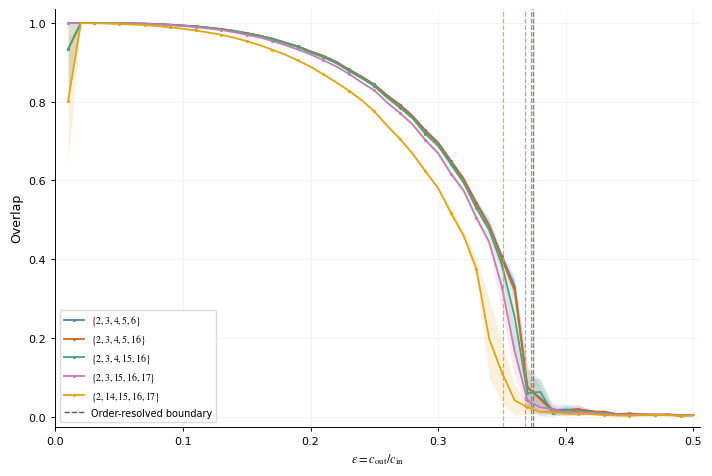

In [6]:
fig = plot_order_sweep(order_data, 'overlap', K, C_2, SHOW_OLD_APPROXIMATION)
save_figure(fig, 'overlap_order_sets',
            f"Overlap for five hyperedge-order sets at N={order_data['N']}, K={K}, c_2={C_2}. "
            f"Curves and shaded bands show the mean and population standard deviation (ddof=0) "
            f"across {len(order_data['seeds'])} sampling seeds. Dashed lines show the order-resolved "
            "linear-stability boundaries; beta_d=1 for every retained order.", [ORDER_FILE])

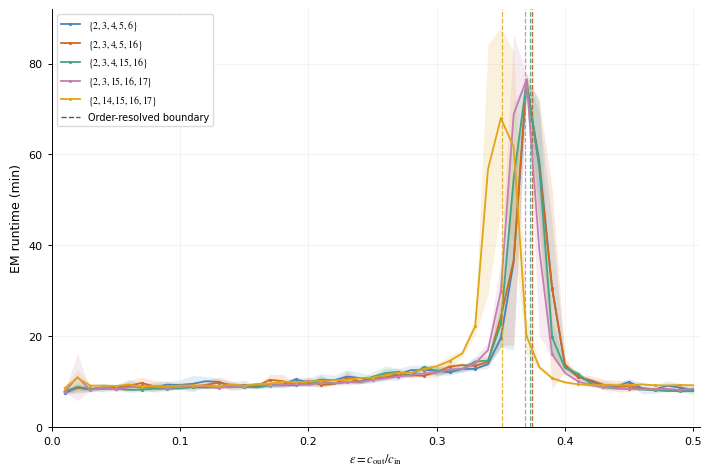

orders,epsilon_order_resolved,epsilon_aggregate,N,seeds
"{2,3,4,5,6}",0.37462,0.36566,30000,5
"{2,3,4,5,16}",0.37399,0.37048,30000,5
"{2,3,4,15,16}",0.37255,0.37755,30000,5
"{2,3,15,16,17}",0.36845,0.38786,30000,5
"{2,14,15,16,17}",0.35095,0.40056,30000,5


In [7]:
fig = plot_order_sweep(order_data, 'time', K, C_2, SHOW_OLD_APPROXIMATION)
save_figure(fig, 'runtime_order_sets',
            f"EM runtime in minutes for the same five order sets at N={order_data['N']}. "
            "Colours match the overlap figure. Curves and bands show mean and population "
            "standard deviation (ddof=0); dashed lines show linear-stability boundaries.", [ORDER_FILE])
order_theory_table = save_table(order_threshold_rows(order_data, K, C_2), 'order_thresholds')

## 5. Theoretical boundaries at fixed incidence budget

Retain the original comparison for $\mathcal{D}=\{2,3\}$ and $\bar{k}_h=3,8$. This section displays zero-truncated $\varepsilon_c^{\mathrm{phys}}$; Section 6 distinguishes empirical boundaries from theoretical boundaries that exist in the physical range.

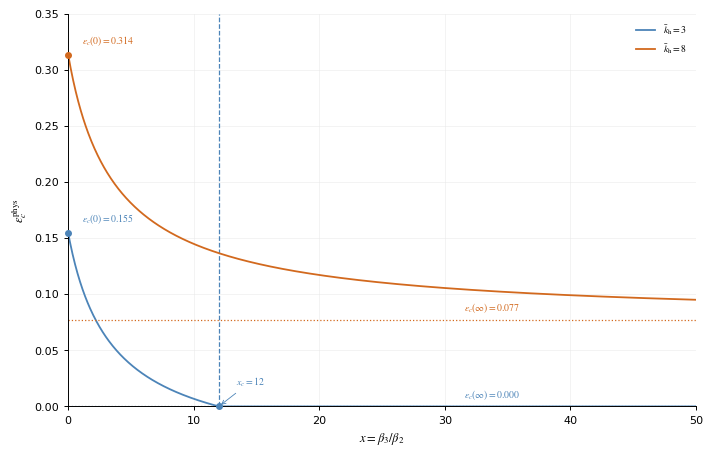

In [8]:
fig = plot_theoretical_collapse(THEORY_KBAR_VALUES, d=3, K=K)
save_figure(fig, 'theoretical_threshold_collapse',
            "Order-resolved physical threshold for D={2,3} under fixed incidence budgets "
            "kbar_h=3 and 8. Dotted lines indicate the x-to-infinity limits; the dashed "
            "vertical line marks finite threshold collapse. Values below zero are clipped "
            "only in this physical-threshold illustration.")

## 6. Fixed budget: theoretical and empirical boundaries

Use the original experiment data for $\bar{k}_h=3,12$. Exclude $\varepsilon=0$, then interpolate between adjacent points where mean Overlap first crosses downward through $Q=0.1$.

`below_range` / `above_range` indicate boundaries outside the scan; table values are scan limits, shown as open triangles rather than exact critical points. `ambiguous_start` marks an initial value below the threshold followed by a rise. `crossing_multiple` still selects the first downward crossing.

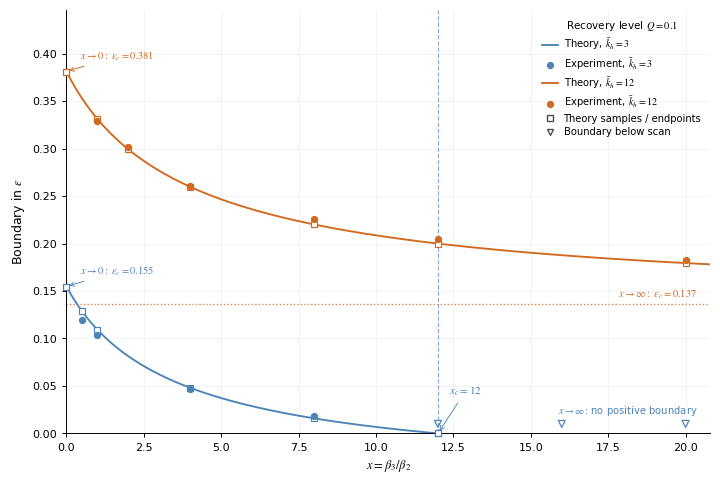

kbar_h,x,empirical,theory,status
3,0.5,0.11987,0.12885,crossing
3,1,0.10401,0.10927,crossing
3,4,0.047271,0.048038,crossing
3,8,0.018037,0.015889,crossing
3,12,0.01,0,below_range
3,16,0.01,NaN,below_range
3,20,0.01,NaN,below_range
12,1,0.3296,0.33126,crossing
12,2,0.30211,0.29923,crossing
12,4,0.26022,0.25977,crossing


In [9]:
fig = plot_fixed_budget(budget_data, Q_LEVEL, K)
save_figure(fig, 'fixed_budget_boundaries',
            f"Recovery and order-resolved BP-stability boundaries for D={{2,3}} at fixed "
            f"incidence budgets kbar_h=3 and 12. Empirical boundaries use the first downward "
            f"crossing of mean overlap at Q={Q_LEVEL:g}, with linear interpolation after "
            "excluding epsilon=0. Open triangles indicate scan limits. Negative theoretical "
            "thresholds do not define a boundary at positive epsilon.", FIXED_BUDGET_FILES)
budget_boundary_table = save_table(budget_boundary_rows, 'fixed_budget_boundaries')

## 7. Order-specific signal compensation

Retain the original 2×3 layout: mean Overlap and theoretical boundaries above, recovery curves at selected $x=\beta_3/\beta_2$ below. White dashed lines show the second-order reference boundary; shading shows standard deviations across seeds.

Despite the `ALLR_mean4` filename, `seed_ids` contains five seeds; the recorded IDs determine the count. Empirical boundaries use the original signal experiment's first-downward-crossing interpolation, retaining NaN when no crossing occurs. They are reported separately from censored statuses in the fixed-budget table.

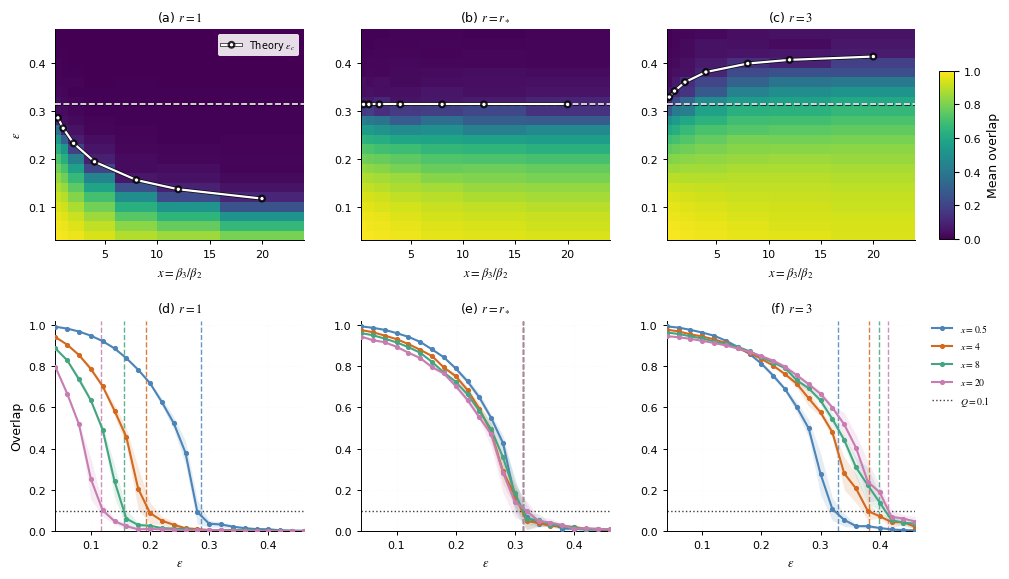

r,x,q_level,eps_theory,eps_empirical
1,0.5,0.1,0.28561,0.27957
1,1,0.1,0.26394,0.25989
1,2,0.1,0.23241,0.23676
1,4,0.1,0.19397,0.19814
1,8,0.1,0.15584,0.15578
1,12,0.1,0.13663,0.13857
1,20,0.1,0.11716,0.12079
2.2125,0.5,0.1,0.31371,0.31388
2.2125,1,0.1,0.31371,0.3144
2.2125,2,0.1,0.31371,0.32185


In [10]:
fig = plot_signal_combined(signal_data, SELECTED_X, Q_LEVEL)
save_figure(fig, 'signal_compensation_2x3_heatmap_curves',
            f"Order-dependent signal compensation at N=10000, K=4 and kbar_h=8. Columns "
            f"show r=1, r=r_star={signal_data['r_star']:.5f}, and r=3. Top: mean overlap "
            f"across {signal_data['seed_count']} seeds; outlined white curves show stored "
            "order-resolved stability boundaries, and white dashed lines show the pairwise "
            "reference. Bottom: mean overlap at selected x values; bands show population "
            "standard deviation (ddof=0), coloured dashed lines show theoretical boundaries, "
            f"and the dotted line marks Q={Q_LEVEL:g}.", [SIGNAL_FILE])
signal_boundaries = save_table(signal_boundary_rows(signal_data, Q_LEVEL), 'signal_boundaries')

## 8. Optional diagnostics and summary rebuilding

Repeated standalone heatmaps, recovery curves, and boundary comparisons are disabled by default. Set `SHOW_SIGNAL_DIAGNOSTICS=True` to display them.

`REBUILD_SIGNAL_SUMMARY=True` summarizes the 15 existing results without rerunning inference. Write the new summary to this run's output directory, preserving historical files. All requested seeds must be present.

In [11]:
if SHOW_SIGNAL_DIAGNOSTICS:
    for stem, fig, caption in plot_signal_diagnostics(signal_data, SELECTED_X, Q_LEVEL):
        save_figure(fig, stem, caption, [SIGNAL_FILE])

if REBUILD_SIGNAL_SUMMARY:
    rebuilt_signal = aggregate_signal_results(SIGNAL_DIR, SIGNAL_SEED_IDS, SIGNAL_R_TAGS, K=K, kbar=8)
    for key in ('overlap_all', 'overlap_mean', 'overlap_std', 'eps_theory'):
        np.testing.assert_allclose(rebuilt_signal[key], signal_data[key], rtol=0, atol=0)
    rebuilt_path = OUTPUT_DIR / f"signal_compensation_summary_{len(SIGNAL_SEED_IDS)}seeds.npz"
    np.savez_compressed(rebuilt_path, **rebuilt_signal)
    print('重新汇总并核对通过：', rebuilt_path)